In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# ==========================================
# 1. LOAD AND CLEAN DATA
# ==========================================
# Open with 'latin-1' encoding (the file contains non-UTF-8 characters)
df = pd.read_csv("retail_data.csv", encoding="latin-1")

# Clean data: drop missing CustomerID, remove cancellations ("C" prefix), and prices <= 0
df = df.dropna(subset=["CustomerID"])
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[df["UnitPrice"] > 0]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [4]:
# ==========================================
# 2. FEATURE ENGINEERING & TARGET CREATION
# ==========================================
# Cutoff date: Sep 1, 2011. Target window: Sept 1 to Dec 9, 2011
cutoff_date = pd.to_datetime("2011-09-01")
end_date = pd.to_datetime("2011-12-09")

train_df = df[df["InvoiceDate"] < cutoff_date].copy()
target_df = df[
    (df["InvoiceDate"] >= cutoff_date) & (df["InvoiceDate"] <= end_date)
]

# Build binary target: 1 if customer purchased in the next 3 months, else 0
repeat_customers = target_df["CustomerID"].unique()
customers = pd.DataFrame(
    {"CustomerID": train_df["CustomerID"].unique()}
)
customers["Will_Buy_Again"] = customers["CustomerID"].isin(
    repeat_customers
).astype(int)

# Pre-calculate Total Price per row for monetary and basket calculations
train_df["TotalPrice"] = train_df["Quantity"] * train_df["UnitPrice"]
snapshot_date = cutoff_date

# Standardized and robust RFM aggregations
rfm = (
    train_df.groupby("CustomerID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (snapshot_date - x.max()).days,
        ),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalPrice", "sum"),
        Unique_Products=("StockCode", "nunique"),
        Avg_Unit_Price=("UnitPrice", "mean"),
        Total_Quantity=("Quantity", "sum"),
    )
    .reset_index()
)

# Calculate Average Basket Value cleanly via invoice-level grouping
invoice_totals = (
    train_df.groupby(["CustomerID", "InvoiceNo"])["TotalPrice"]
    .sum()
    .reset_index()
)
avg_basket = (
    invoice_totals.groupby("CustomerID")["TotalPrice"]
    .mean()
    .reset_index()
    .rename(columns={"TotalPrice": "Avg_Basket_Value"})
)

# Merge average basket value into rfm dataframe
rfm = pd.merge(rfm, avg_basket, on="CustomerID")

# Merge features with target variable
model_df = pd.merge(customers, rfm, on="CustomerID", how="inner")

X = model_df.drop(columns=["CustomerID", "Will_Buy_Again"])
y = model_df["Will_Buy_Again"]

# Train/Test Split (stratified to preserve class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [5]:
# ==========================================
# 3. CLASSIFICATION PIPELINE & MODEL
# ==========================================
clf_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
            ),
        ),
    ]
)

# Train model
clf_pipeline.fit(X_train, y_train)

# Predictions
y_pred = clf_pipeline.predict(X_test)
y_prob = clf_pipeline.predict_proba(X_test)[:, 1]

# Evaluation Metrics
print("--- E-Commerce Classification Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

--- E-Commerce Classification Performance ---
Accuracy: 0.6657
ROC-AUC: 0.7247

Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.61      0.60       274
           1       0.72      0.71      0.71       390

    accuracy                           0.67       664
   macro avg       0.66      0.66      0.66       664
weighted avg       0.67      0.67      0.67       664



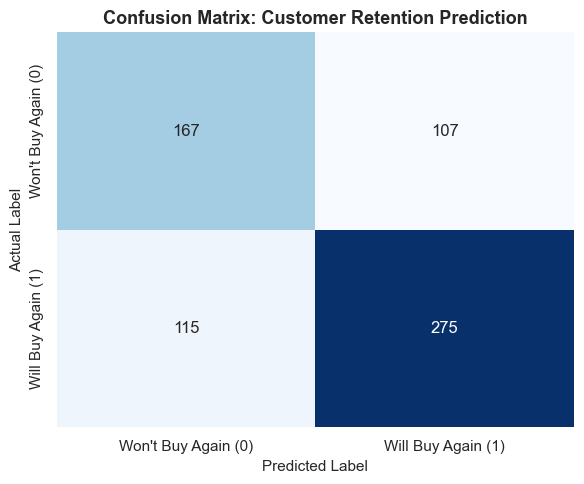

In [6]:
# ==========================================
# 4. DATA VISUALIZATIONS
# ==========================================
sns.set_theme(style="whitegrid")

# Plot 1: Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Won't Buy Again (0)", "Will Buy Again (1)"],
    yticklabels=["Won't Buy Again (0)", "Will Buy Again (1)"],
)
plt.title(
    "Confusion Matrix: Customer Retention Prediction",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)
plt.tight_layout()
plt.savefig("retail_confusion_matrix.png", dpi=300)
plt.show()

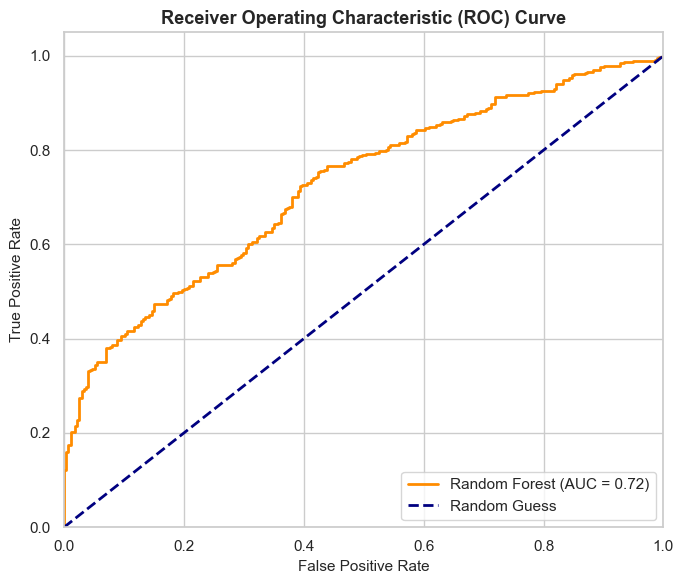

In [7]:
# Plot 2: ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    color="darkorange",
    lw=2,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob):.2f})",
)
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Guess")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.title(
    "Receiver Operating Characteristic (ROC) Curve",
    fontsize=13,
    fontweight="bold",
)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.savefig("retail_roc_curve.png", dpi=300)
plt.show()

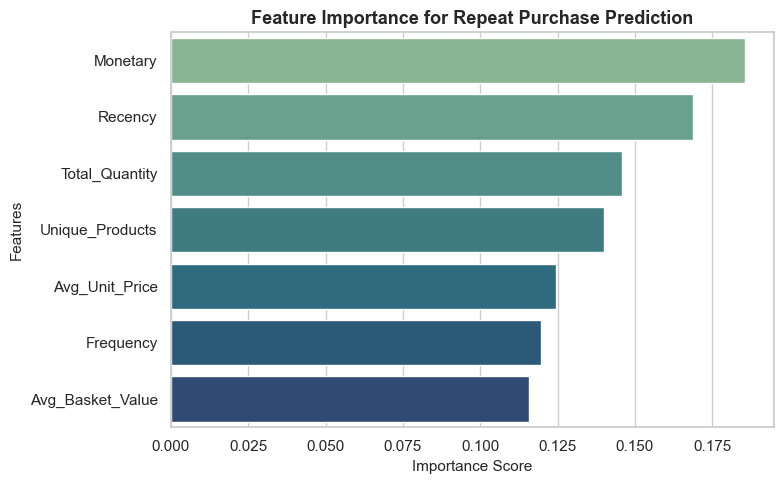

In [8]:
# Plot 3: Feature Importances
importances = clf_pipeline.named_steps["classifier"].feature_importances_
features_list = X.columns.tolist()
feat_imp_df = pd.DataFrame(
    {"Feature": features_list, "Importance": importances}
).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feat_imp_df,
    palette="crest",
    hue="Feature",
    legend=False,
)
plt.title(
    "Feature Importance for Repeat Purchase Prediction",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Importance Score", fontsize=11)
plt.ylabel("Features", fontsize=11)
plt.tight_layout()
plt.savefig("retail_feature_importance.png", dpi=300)
plt.show()

In [9]:
# ==========================================
# 1. LOAD DATA & CLEANING FOR EDA
# ==========================================
# Open with 'latin-1' encoding as required for this dataset
df = pd.read_csv("retail_data.csv", encoding="latin-1")

print("--- DATASET OVERVIEW ---")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"Missing Values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")

# Clean data for valid exploratory insights: remove cancellations and non-positive prices
clean_df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()
clean_df = clean_df[clean_df["UnitPrice"] > 0]
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"])
clean_df["TotalPrice"] = clean_df["Quantity"] * clean_df["UnitPrice"]

print(f"Cleaned Rows for EDA: {clean_df.shape[0]}")

# Setup plotting theme
sns.set_theme(style="whitegrid")

--- DATASET OVERVIEW ---
Total Rows: 541909
Total Columns: 8
Missing Values:
Description      1454
CustomerID     135080
dtype: int64
Cleaned Rows for EDA: 530104


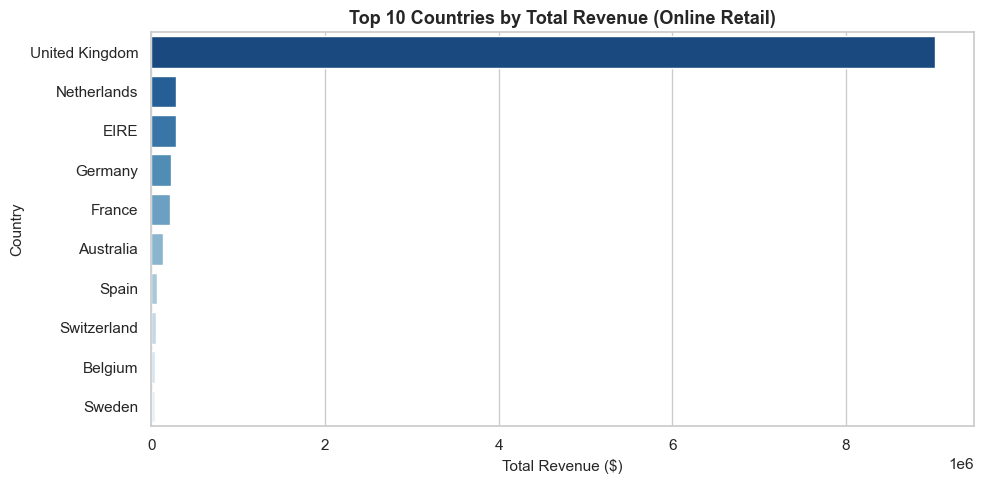

[Takeaway 1] The United Kingdom dominates total sales volume by a massive margin (~91% of customers), confirming that regional skewness must be accounted for in modeling.


In [10]:
# ==========================================
# 2. FIVE MEANINGFUL EDA PLOTS & TAKEAWAYS
# ==========================================

# --- Plot 1: Top 10 Countries by Total Sales Volume ---
plt.figure(figsize=(10, 5))
top_countries = (
    clean_df.groupby("Country")["TotalPrice"]
    .sum()
    .reset_index()
    .sort_values(by="TotalPrice", ascending=False)
    .head(10)
)
sns.barplot(
    data=top_countries,
    x="TotalPrice",
    y="Country",
    palette="Blues_r",
    hue="Country",
    legend=False,
)
plt.title(
    "Top 10 Countries by Total Revenue (Online Retail)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Total Revenue ($)", fontsize=11)
plt.ylabel("Country", fontsize=11)
plt.tight_layout()
plt.savefig("eda_retail_top_countries.png", dpi=300)
plt.show()
print(
    "[Takeaway 1] The United Kingdom dominates total sales volume by a massive margin (~91% of customers), confirming that regional skewness must be accounted for in modeling."
)

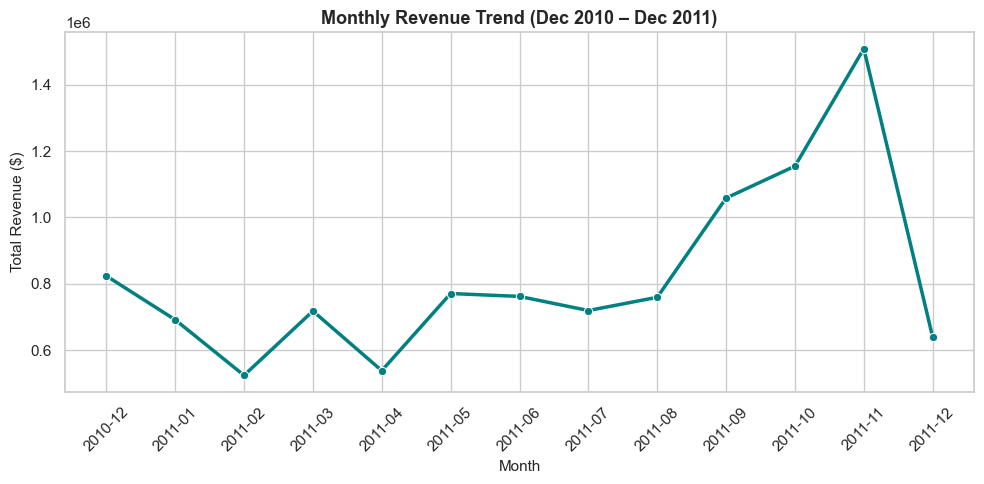

[Takeaway 2] Revenue shows significant seasonal surges toward the final quarter of the year, peaking sharply around October and November before the holiday cutoff.


In [11]:
# --- Plot 2: Monthly Revenue Trend ---
plt.figure(figsize=(10, 5))
clean_df["YearMonth"] = clean_df["InvoiceDate"].dt.to_period("M")
monthly_revenue = (
    clean_df.groupby("YearMonth")["TotalPrice"].sum().reset_index()
)
monthly_revenue["YearMonth"] = monthly_revenue["YearMonth"].astype(str)

sns.lineplot(
    data=monthly_revenue,
    x="YearMonth",
    y="TotalPrice",
    marker="o",
    color="teal",
    linewidth=2.5,
)
plt.title("Monthly Revenue Trend (Dec 2010 – Dec 2011)", fontsize=13, fontweight="bold")
plt.xlabel("Month", fontsize=11)
plt.ylabel("Total Revenue ($)", fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("eda_retail_monthly_revenue.png", dpi=300)
plt.show()
print(
    "[Takeaway 2] Revenue shows significant seasonal surges toward the final quarter of the year, peaking sharply around October and November before the holiday cutoff."
)

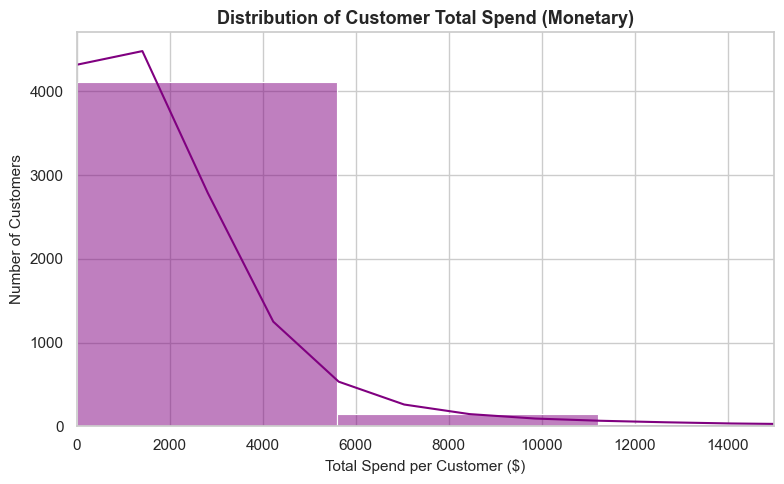

[Takeaway 3] Customer monetary value is heavily right-skewed; the majority of active buyers have modest lifetime spend totals, while a small group of high-value clients drives bulk revenue.


In [12]:
# --- Plot 3: Distribution of Customer Monetary Value (Total Spend) ---
plt.figure(figsize=(8, 5))
customer_spend = clean_df.groupby("CustomerID")["TotalPrice"].sum().reset_index()
sns.histplot(customer_spend["TotalPrice"], kde=True, color="purple", bins=50)
plt.xlim(0, 15000)  # Zoom in on main distribution excluding wholesale outliers
plt.title("Distribution of Customer Total Spend (Monetary)", fontsize=13, fontweight="bold")
plt.xlabel("Total Spend per Customer ($)", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)
plt.tight_layout()
plt.savefig("eda_retail_customer_spend.png", dpi=300)
plt.show()
print(
    "[Takeaway 3] Customer monetary value is heavily right-skewed; the majority of active buyers have modest lifetime spend totals, while a small group of high-value clients drives bulk revenue."
)

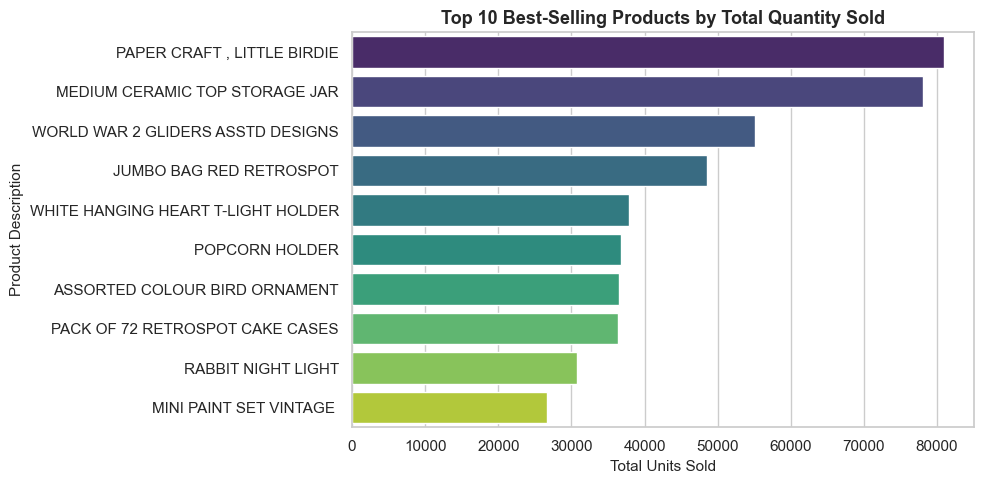

[Takeaway 4] Best-selling items consist predominantly of popular household decorative items, promotional packs, and party goods sold in high volume.


In [13]:
# --- Plot 4: Top 10 Best-Selling Products by Quantity ---
plt.figure(figsize=(10, 5))
top_products = (
    clean_df.groupby("Description")["Quantity"]
    .sum()
    .reset_index()
    .sort_values(by="Quantity", ascending=False)
    .head(10)
)
sns.barplot(
    data=top_products,
    x="Quantity",
    y="Description",
    palette="viridis",
    hue="Description",
    legend=False,
)
plt.title("Top 10 Best-Selling Products by Total Quantity Sold", fontsize=13, fontweight="bold")
plt.xlabel("Total Units Sold", fontsize=11)
plt.ylabel("Product Description", fontsize=11)
plt.tight_layout()
plt.savefig("eda_retail_top_products.png", dpi=300)
plt.show()
print(
    "[Takeaway 4] Best-selling items consist predominantly of popular household decorative items, promotional packs, and party goods sold in high volume."
)

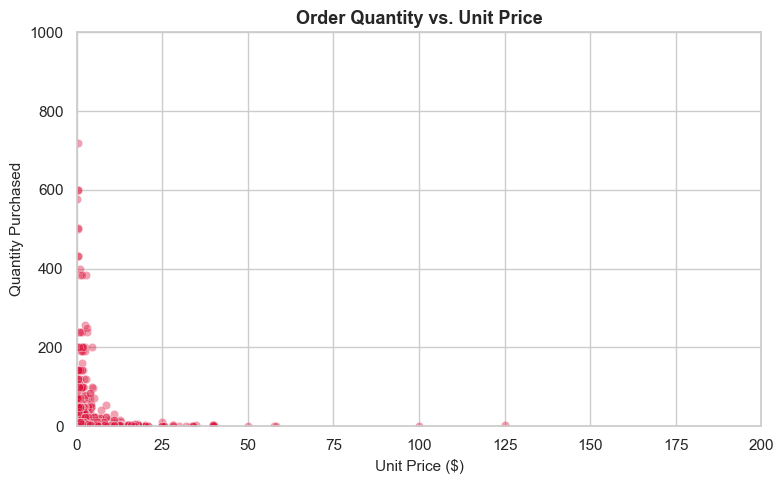

[Takeaway 5] Large quantity orders are strictly associated with low unit-price items (bulk retail/wholesale behavior), whereas high unit-price items are purchased in small quantities.


In [14]:
# --- Plot 5: Order Size vs. Unit Price Scatter Plot ---
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=clean_df.sample(5000, random_state=42),  # Sample for clean rendering
    x="UnitPrice",
    y="Quantity",
    alpha=0.4,
    color="crimson",
)
plt.ylim(0, 1000)
plt.xlim(0, 200)
plt.title("Order Quantity vs. Unit Price", fontsize=13, fontweight="bold")
plt.xlabel("Unit Price ($)", fontsize=11)
plt.ylabel("Quantity Purchased", fontsize=11)
plt.tight_layout()
plt.savefig("eda_retail_price_vs_qty.png", dpi=300)
plt.show()
print(
    "[Takeaway 5] Large quantity orders are strictly associated with low unit-price items (bulk retail/wholesale behavior), whereas high unit-price items are purchased in small quantities."
)